# Computational Exercise 8

## Base code
First, we code the functions we're using through the exercise. The first one is "CreateMesh", which was already on "solve_CDR.py", with the slight change that now it's possible to choose the characteristic size of the mesh. The second is "solve_CDR", which receive all possible parameters and solve the CDR BVP, saving the solution. The last one plots the functions using pyvista

PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
/tmp/ipykernel_90567/2261322511.py:207: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


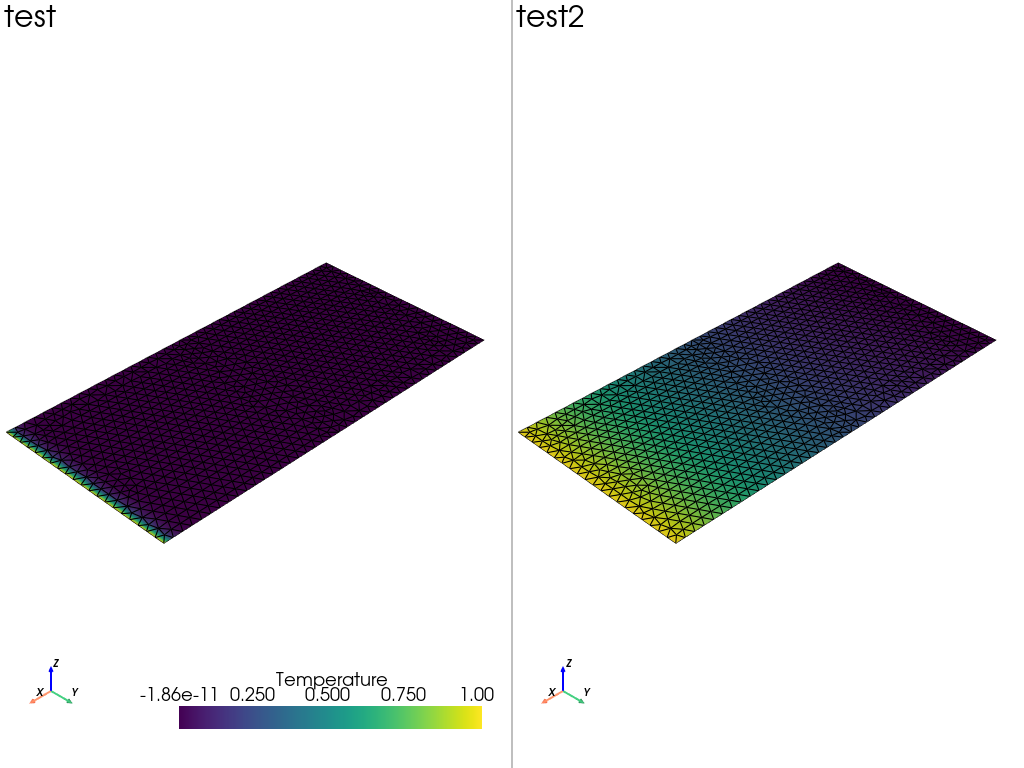

In [22]:
import firedrake as fd
from firedrake.output import VTKFile 
import pyvista as pv

import gmsh
import numpy as np

def innerH1(u, v):
    return (fd.inner(u,v) + fd.inner(fd.grad(u), fd.grad(v))) * fd.dx

def H1norm(u):
    return np.sqrt(fd.assemble(innerH1(u,u)))


#--------------------------------------------------------------------
#--- Preprocess: Mesh generation, boundary and region identification

leftdom_marker = 2
rightdom_marker = 1
leftwall_marker = 1
rightwall_marker = 0

def CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, file_name:str, r:float=0.05):
    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    # We create one rectangle for each subdomain
    gmsh.model.occ.addRectangle(0, 0, 0, Lx/2, Ly, tag=1)
    gmsh.model.occ.addRectangle(Lx/2, 0, 0, Lx/2, Ly, tag=2)
    # We fuse the two rectangles and keep the interface between them 
    whole_domain = gmsh.model.occ.fragment([(2,1)],[(2,2)])
    gmsh.model.occ.synchronize()
   
    # Mark the left and right subdomains
    leftdom, rightdom = [], [] # None, None
    for surface in whole_domain[0]:
        com = gmsh.model.occ.getCenterOfMass(surface[0], surface[1])
        if np.allclose(com, [Lx/4,Ly/2, 0]):
            leftdom.append(surface)
            gmsh.model.addPhysicalGroup(2, [surface[1]], leftdom_marker)
        else:
            rightdom.append(surface)
            gmsh.model.addPhysicalGroup(2, [surface[1]], rightdom_marker)

    # Tag the left and right boundaries
    leftwall, rightwall, interface = [], [], []
    for line in gmsh.model.getEntities(dim=1):
        com = gmsh.model.occ.getCenterOfMass(line[0], line[1])
        if np.isclose(com[0], 0):
            leftwall.append(line[1])
        if np.isclose(com[0], Lx):
            rightwall.append(line[1])
        if np.isclose(com[0], Lx/2):
            interface.append(line[1])
    gmsh.model.addPhysicalGroup(1, leftwall, leftwall_marker)
    gmsh.model.addPhysicalGroup(1, rightwall, rightwall_marker)

    if(flag_refine_exit):
        gmsh.model.mesh.field.add("Distance", 1)
        gmsh.model.mesh.field.setNumbers(1, "EdgesList", rightwall)
        gmsh.model.mesh.field.add("Threshold", 2)
        gmsh.model.mesh.field.setNumber(2, "IField", 1)
        
        gmsh.model.mesh.field.setNumber(2, "LcMin", r / 2)
        gmsh.model.mesh.field.setNumber(2, "LcMax", 1.5 * r)
        gmsh.model.mesh.field.setNumber(2, "DistMin", 2 * r)
        gmsh.model.mesh.field.setNumber(2, "DistMax", 4 * r)
        gmsh.model.mesh.field.setAsBackgroundMesh(2)
    elif(flag_refine_interface):
        gmsh.model.mesh.field.add("Distance", 1)
        gmsh.model.mesh.field.setNumbers(1, "EdgesList", interface)
        gmsh.model.mesh.field.add("Threshold", 2)
        gmsh.model.mesh.field.setNumber(2, "IField", 1)

        gmsh.model.mesh.field.setNumber(2, "LcMin", r / 2)
        gmsh.model.mesh.field.setNumber(2, "LcMax", 1.5 * r)
        gmsh.model.mesh.field.setNumber(2, "DistMin", 2 * r)
        gmsh.model.mesh.field.setNumber(2, "DistMax", 4 * r)
        gmsh.model.mesh.field.setAsBackgroundMesh(2)
    else:
        gmsh.model.mesh.setSize(gmsh.model.getEntities(0), r)
            
    gmsh.option.setNumber("Mesh.Algorithm", 6)
    gmsh.model.mesh.generate(2)
    gmsh.write(file_name)
    gmsh.finalize()
    mesh = fd.Mesh(file_name)
    
    return mesh
    
#--- End preprocessing
#-------------------------------------------------

#-------------------------------------------------
# Convection-Diffusion-Reaction (CDR) problem

def solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, save_name):
    V = fd.FunctionSpace(mymesh, "CG", degree=1)
    u, v = fd.TrialFunction(V), fd.TestFunction(V)


    a  = fd.inner(kappa*fd.grad(u), fd.grad(v)) * fd.dx

    bcs = []
    if  (icase == 'REAC_BL'): # Reaction and Source term
        sigma = fd.Constant(sigma_val)
        a += sigma * u * v * fd.dx
        #---------------------------------------------------------------------------
        # Auxiliary problem to define a piecewise constant function
        Qh = fd.FunctionSpace(mymesh, "DG", degree=0)
        sourceT = fd.TrialFunction(Qh)
        vp = fd.TestFunction(Qh)
        ap = sourceT*vp*fd.dx
        sourceL, sourceR = 0.0, sigma_val
        Lp = fd.Constant(sourceL)*vp*fd.dx(leftdom_marker)
        Lp += fd.Constant(sourceR)*vp*fd.dx(rightdom_marker)
        source = fd.Function(Qh, name='sigma')
        opts={"ksp_type": "preonly", "pc_type": "lu", "pc_factor_mat_solver_type": "mumps"}
        fd.solve(ap==Lp, source, bcs=[], solver_parameters=opts)
        #--------------------------------------------------------------------------
        L = source*v*fd.dx
        beta = fd.as_vector([0.0, 0.0])

    elif(icase == 'CONV_BL'): # Convective term
        sigma = fd.Constant(0.0)
        a = a + fd.inner(beta, fd.grad(u)) * v * fd.dx
        source = fd.Constant(0.0)
        L = source*v*fd.dx
        bcs.append(fd.DirichletBC(V, fd.Constant(0.0),leftwall_marker))
        bcs.append(fd.DirichletBC(V, fd.Constant(1.0), rightwall_marker))
        
    if(iestab == 'SUPG'): # Stabilization
        hk = fd.CellDiameter(mymesh)
        tauk = 1.0/(4*kappa/hk**2 + 2.0*fd.sqrt(fd.dot(beta,beta))/hk + sigma)
        
        lhs_eq = -fd.div(kappa*fd.grad(u)) + fd.dot(beta,fd.grad(u)) + sigma*u
        rhs_eq = source
        perturbed = fd.inner(beta, fd.grad(v))

        a = a + tauk * lhs_eq * perturbed * fd.dx(domain=mymesh)
        L = L + tauk * rhs_eq * perturbed * fd.dx(domain=mymesh)

    # Solve the problem
    uh = fd.Function(V, name='Temperature')
    opts={"ksp_type": "preonly", "pc_type": "lu", "pc_factor_mat_solver_type": "mumps"}
    fd.solve(a == L, uh, bcs=bcs, solver_parameters=opts)

    # Save the results
    VTKFile(save_name).write(uh)

    return uh

def plot_function(
    file_name,
    title,
    plotter,
    pos1,
    pos2,
    surface: bool = True
):
    grid = pv.read(file_name)

    # Select the subplot
    plotter.subplot(pos1, pos2)

    # Extract the mesh if the file contains a MultiBlock
    mesh = grid[0] if isinstance(grid, pv.MultiBlock) else grid

    if surface:
        # 3D surface plot
        mesh = mesh.warp_by_scalar("Temperature", factor=1.0)

    plotter.add_mesh(
        mesh,
        scalars="Temperature",
        show_edges=True,
        cmap="viridis",
        show_scalar_bar=True,
    )
    plotter.add_text(title, font_size=12)
    plotter.show_axes()

Lx, Ly = 2.0, 1.0
flag_refine_exit = False
flag_refine_interface = False
mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh")


#icase = 'REAC_BL'
icase = 'CONV_BL'
iestab = 'SUPG'
#iestab = 'NONE'

# Diffusive term
kappa = fd.Constant(1.0e-2)
sigma_val = 1.0
beta = fd.as_vector([1.0, 0.0])

solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, "Solutions/test.pvd")

kappa = fd.Constant(1.0)
solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, "Solutions/test2.pvd")

plotter = pv.Plotter(shape=(1,2))
plot_function("Solutions/test.pvd", "test", plotter, 0, 0, False)
plot_function("Solutions/test2.pvd", "test2", plotter, 0, 1, False)
plotter.link_views()
plotter.show()




## Exercise 1

### a)
- $L = 2$
- $\kappa = 1$
- $\sigma \in \{1, 10, 100, 1000, 10000\}$

Using $h_K = 0.1$

PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
/tmp/ipykernel_90567/3573252648.py:23: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


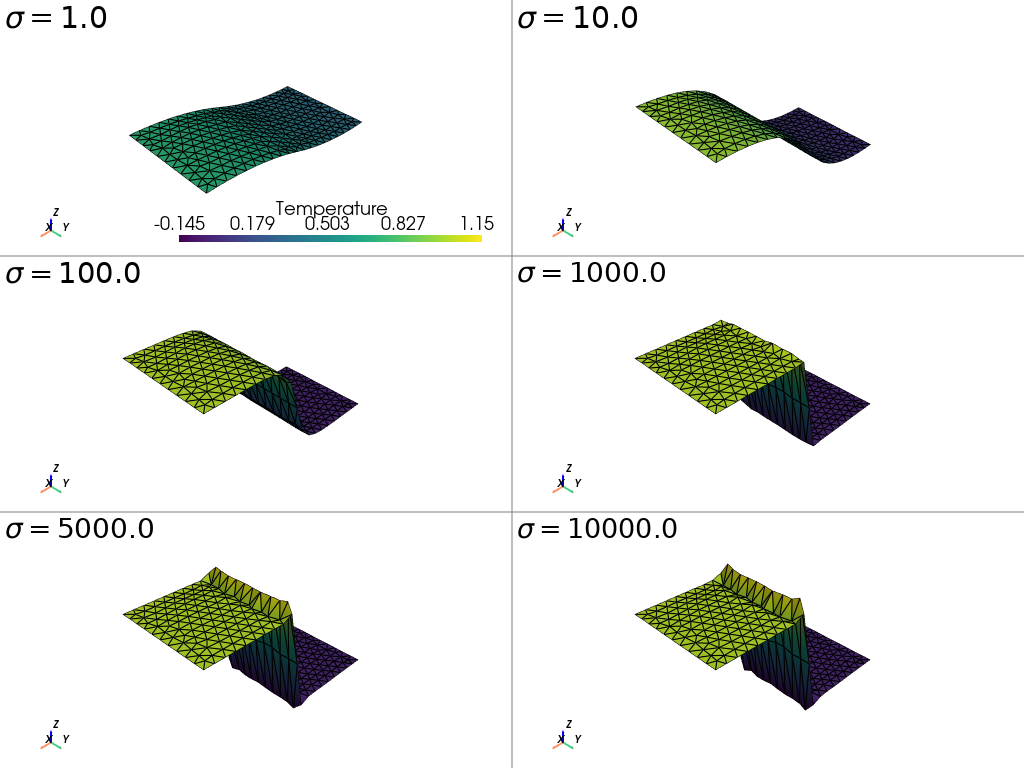

In [7]:
Lx, Ly = 2.0, 1.0
flag_refine_exit = False
flag_refine_interface = False
mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh", 0.1)
VTKFile('mymesh.pvd').write(mymesh)

icase = 'REAC_BL'
#icase = 'CONV_BL'
#iestab = 'SUPG'
iestab = 'NONE'

# Diffusive term
kappa = fd.Constant(1.0)
lsigma_val = [1.0, 10.0, 100.0, 1000.0, 5000.0, 10000.0]
beta = fd.as_vector([1.0, 0.0])

plotter = pv.Plotter(shape=(3,2))
for i, sigma_val in enumerate(lsigma_val):
    solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, f"Solutions/{sigma_val:.1f}.pvd")

    plot_function(f"Solutions/{sigma_val:.1f}.pvd", rf"$\sigma = {sigma_val}$", plotter, i//2, i%2, True)
plotter.link_views()
plotter.show()

### b)
Comparating with the analytical solution: 

$u(x) = \begin{cases}
1 - \dfrac12 e^{-\dfrac{x-1}{\delta_r}} , \text{ if } x \ge 1 \\
\\
\dfrac12 e^{\dfrac{x-1}{\delta_r}}, \text{ if } x < 1
\end{cases}$

Where $\delta_r = \sqrt{\dfrac{\kappa}{\sigma}}$

In [13]:
from tabulate import tabulate

Lx, Ly = 2.0, 1.0
flag_refine_exit = False
flag_refine_interface = False


icase = 'REAC_BL'
#icase = 'CONV_BL'
#iestab = 'SUPG'
iestab = 'NONE'

# Diffusive term
kappa = fd.Constant(1.0)
lsigma_val = [1.0, 10.0, 100.0, 1000.0, 5000.0, 10000.0]
beta = fd.as_vector([1.0, 0.0])

lh = [0.25, 0.125, 0.0625, 0.03125]

lerrors = {sigma: [] for sigma in lsigma_val}

for i, sigma_val in enumerate(lsigma_val):
    for j, h in enumerate(lh):
        mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh", h)
        
        Vh = fd.FunctionSpace(mymesh, "CG", degree=1)

        u,v = fd.TrialFunction(Vh), fd.TestFunction(Vh)
        x = fd.SpatialCoordinate(mymesh)

        deltar = fd.sqrt(kappa/ fd.Constant(sigma_val))
        Lex = (fd.Constant(1.0) - fd.Constant(0.5) * fd.exp(- (x[0] - 1.0)/deltar)) * v * fd.dx(rightdom_marker)
        Lex += fd.Constant(0.5) * fd.exp((x[0] - 1.0)/deltar) * v * fd.dx(leftdom_marker)
        aex = u * v * fd.dx

        uex = fd.Function(Vh)
        opts={"ksp_type": "preonly", "pc_type": "lu", "pc_factor_mat_solver_type": "mumps"}
        fd.solve(aex==Lex, uex, bcs=[], solver_parameters=opts)
        
        uh = solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, f"Solutions/placeholder.pvd")

        error = H1norm(uex - uh)
        lerrors[sigma_val].append(error)

header = ["h"]
for sigma in lsigma_val:
    header.append(sigma)

lines = []

for i, h in enumerate(lh):
    l_tmp = [h]
    for sigma, l in lerrors.items():
        l_tmp.append(l[i])
    lines.append(l_tmp)

print("Errors in the H1 norm (each collumn is a sigma)")
print(tabulate(lines, headers=header))


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and 

Errors in the H1 norm (each collumn is a sigma)
      h       1.0       10.0      100.0    1000.0    5000.0    10000.0
-------  --------  ---------  ---------  --------  --------  ---------
0.25     0.227494  0.0617816  0.200522   0.131149  0.0324    0.0179065
0.125    0.22717   0.0444875  0.131276   0.251554  0.118464  0.0644003
0.0625   0.22704   0.0403741  0.0675522  0.294736  0.333369  0.255095
0.03125  0.227021  0.0398333  0.0299536  0.200159  0.46059   0.517045


### c)

Activating local mesh refinement at the interface:

In [14]:
Lx, Ly = 2.0, 1.0
flag_refine_exit = False
flag_refine_interface = True


icase = 'REAC_BL'
#icase = 'CONV_BL'
#iestab = 'SUPG'
iestab = 'NONE'

# Diffusive term
kappa = fd.Constant(1.0)
lsigma_val = [1.0, 10.0, 100.0, 1000.0, 5000.0, 10000.0]
beta = fd.as_vector([1.0, 0.0])

lh = [0.25, 0.125, 0.0625, 0.03125]

lerrors = {sigma: [] for sigma in lsigma_val}

for i, sigma_val in enumerate(lsigma_val):
    for j, h in enumerate(lh):
        mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh", h)
        
        Vh = fd.FunctionSpace(mymesh, "CG", degree=1)

        u,v = fd.TrialFunction(Vh), fd.TestFunction(Vh)
        x = fd.SpatialCoordinate(mymesh)

        deltar = fd.sqrt(kappa/ fd.Constant(sigma_val))
        Lex = (fd.Constant(1.0) - fd.Constant(0.5) * fd.exp(- (x[0] - 1.0)/deltar)) * v * fd.dx(rightdom_marker)
        Lex += fd.Constant(0.5) * fd.exp((x[0] - 1.0)/deltar) * v * fd.dx(leftdom_marker)
        aex = u * v * fd.dx

        uex = fd.Function(Vh)
        opts={"ksp_type": "preonly", "pc_type": "lu", "pc_factor_mat_solver_type": "mumps"}
        fd.solve(aex==Lex, uex, bcs=[], solver_parameters=opts)
        
        uh = solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, f"Solutions/placeholder.pvd")

        error = H1norm(uex - uh)
        lerrors[sigma_val].append(error)

header = ["h"]
for sigma in lsigma_val:
    header.append(sigma)

lines = []

for i, h in enumerate(lh):
    l_tmp = [h]
    for sigma, l in lerrors.items():
        l_tmp.append(l[i])
    lines.append(l_tmp)

print("Errors in the H1 norm (each collumn is a sigma)")
print(tabulate(lines, headers=header))


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and 

Errors in the H1 norm (each collumn is a sigma)
      h       1.0       10.0      100.0     1000.0    5000.0    10000.0
-------  --------  ---------  ---------  ---------  --------  ---------
0.25     0.227387  0.0439107  0.13916    0.314794   0.167636  0.0979695
0.125    0.227322  0.039903   0.0713084  0.319458   0.375757  0.293634
0.0625   0.227106  0.039551   0.0307953  0.204804   0.481609  0.550313
0.03125  0.227034  0.0396795  0.0120667  0.0960165  0.338246  0.514387


Similar errors. With $\sigma \in \{100, 1000\}$, the refining at the interface gives an smaller error, while with $\sigma = 10000$, the error is bigger.

## Exercise 2

### a)
- $\beta = [1,0]^\top$
- $h = 1/32$
- $\kappa \in \{0.001, 1\}$
- Uniform mesh

PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
/tmp/ipykernel_90567/2214849959.py:23: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


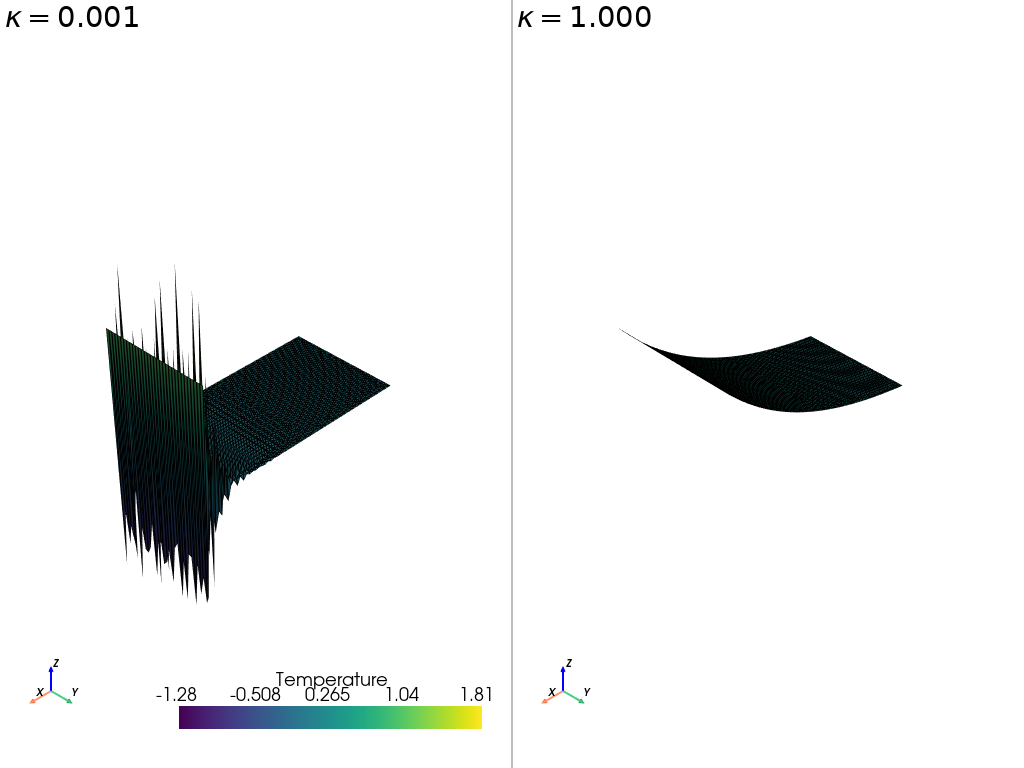

In [16]:
Lx, Ly = 2.0, 1.0
flag_refine_exit = False
flag_refine_interface = False
mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh", 1.0/32.0)
VTKFile('mymesh.pvd').write(mymesh)

#icase = 'REAC_BL'
icase = 'CONV_BL'
#iestab = 'SUPG'
iestab = 'NONE'

# Diffusive term
lkappa = [fd.Constant(0.001), fd.Constant(1.0)]
sigma_val = fd.Constant(0.0)
beta = fd.as_vector([1.0, 0.0])

plotter = pv.Plotter(shape=(1,2))
for i, kappa in enumerate(lkappa):
    solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, f"Solutions/{float(kappa):.3f}.pvd")

    plot_function(f"Solutions/{float(kappa):.3f}.pvd", rf"$\kappa = {float(kappa):.3f}$", plotter, 0, i, True)
plotter.link_views()
plotter.show()

The solution gets wavy as $\kappa \to 0$

### b)

- $\kappa = 0.01$

Refining the mesh uniformly

PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.0625 - H1 error =  3.5973894615025706
h = 0.03125 - H1 error =  1.848805504592057


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.015625 - H1 error =  0.6471603761438136


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.0078125 - H1 error =  0.18079036210217955


/tmp/ipykernel_90567/3361688704.py:30: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


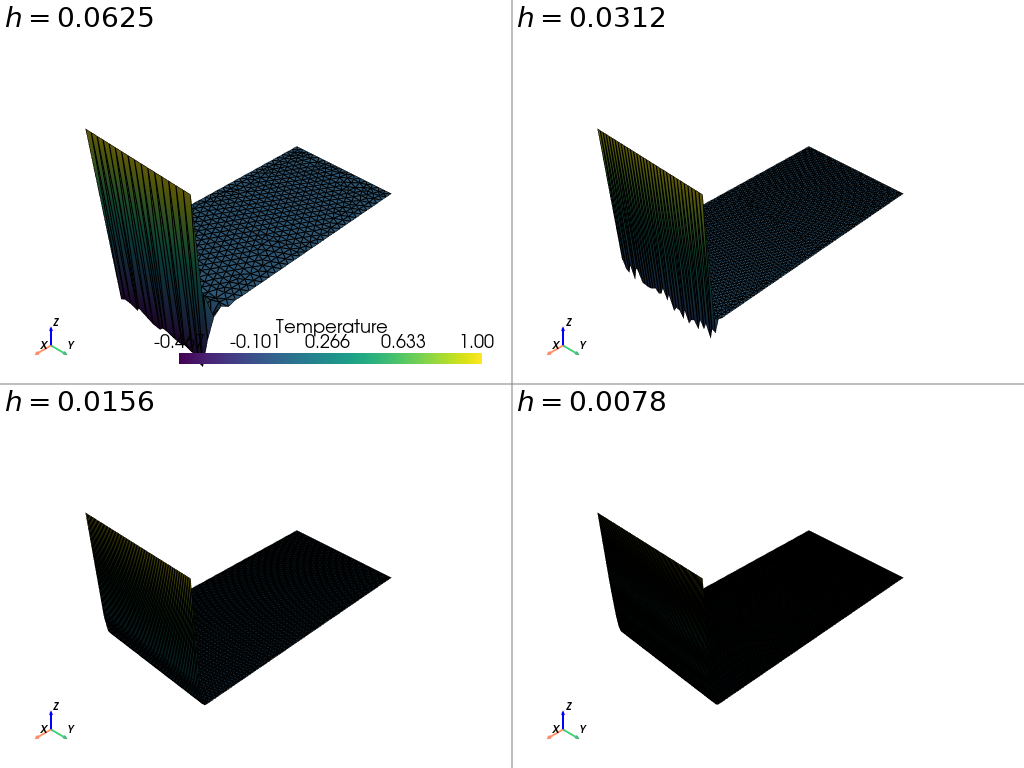

In [31]:
Lx, Ly = 2.0, 1.0
flag_refine_exit = False
flag_refine_interface = False


#icase = 'REAC_BL'
icase = 'CONV_BL'
#iestab = 'SUPG'
iestab = 'NONE'

# Diffusive term
kappa = fd.Constant(0.01)
sigma_val = fd.Constant(0.0)
beta = fd.as_vector([1.0, 0.0])

lh = [1.0/16.0, 1.0/32.0, 1.0/64.0, 1.0/128.0]

plotter = pv.Plotter(shape=(2,2))
for i, h in enumerate(lh):
    mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh", h)
    Vh = fd.FunctionSpace(mymesh, "CG", degree=1)
    Pe = fd.sqrt(beta[0]**2 + beta[1]**2) * Lx / kappa
    uex = fd.Function(Vh)
    uex.interpolate((fd.exp(Pe*x[0]/Lx) -1) / (fd.exp(Pe) - 1))
    uh = solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, f"Solutions/{h:.4f}.pvd")

    plot_function(f"Solutions/{h:.4f}.pvd", rf"$h = {h:.4f}$", plotter, i//2, i%2, True)
    print(f"h = {h} - H1 error = ", H1norm(uex - uh))
plotter.link_views()
plotter.show()

### c)

Refining near the exit

PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.0625 - H1 error =  1.8877702893638728
h = 0.03125 - H1 error =  0.6636922824553628


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.015625 - H1 error =  0.2597523198679777


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.0078125 - H1 error =  0.12411470709154811


/tmp/ipykernel_90567/1491375164.py:30: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


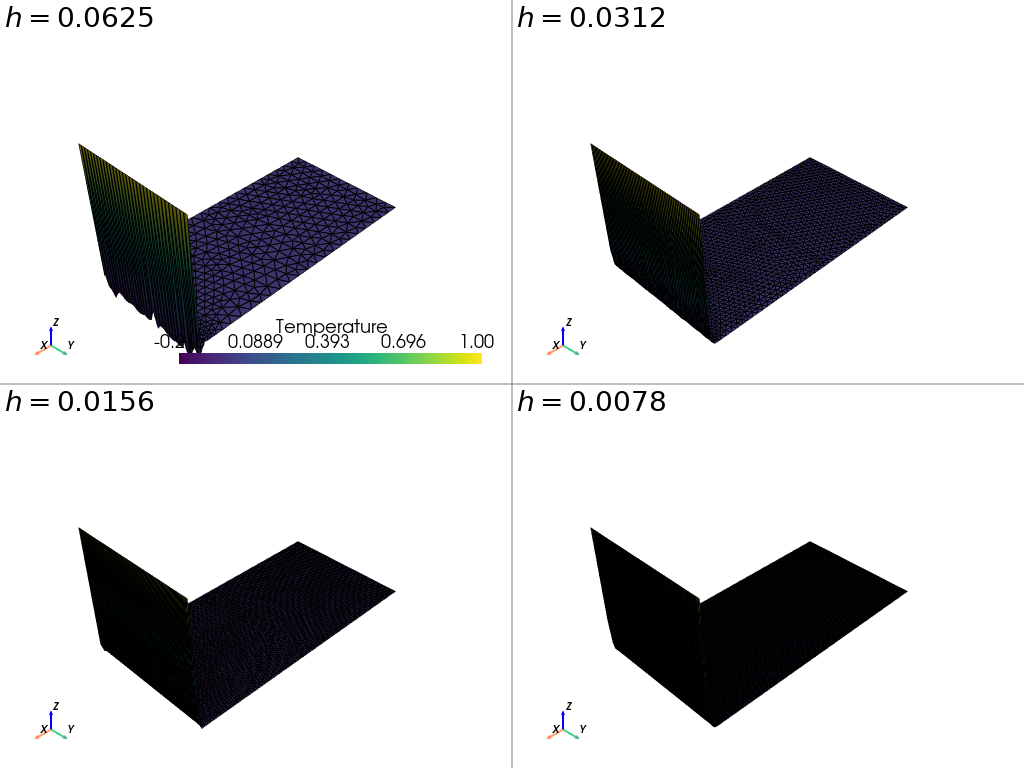

In [33]:
Lx, Ly = 2.0, 1.0
flag_refine_exit = True
flag_refine_interface = False


#icase = 'REAC_BL'
icase = 'CONV_BL'
#iestab = 'SUPG'
iestab = 'NONE'

# Diffusive term
kappa = fd.Constant(0.01)
sigma_val = fd.Constant(0.0)
beta = fd.as_vector([1.0, 0.0])

lh = [1.0/16.0, 1.0/32.0, 1.0/64.0, 1.0/128.0]

plotter = pv.Plotter(shape=(2,2))
for i, h in enumerate(lh):
    mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh", h)
    Vh = fd.FunctionSpace(mymesh, "CG", degree=1)
    Pe = fd.sqrt(beta[0]**2 + beta[1]**2) * Lx / kappa
    uex = fd.Function(Vh)
    uex.interpolate((fd.exp(Pe*x[0]/Lx) -1) / (fd.exp(Pe) - 1))
    uh = solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, f"Solutions/{h:.4f}.pvd")

    plot_function(f"Solutions/{h:.4f}.pvd", rf"$h = {h:.4f}$", plotter, i//2, i%2, True)
    print(f"h = {h} - H1 error = ", H1norm(uex - uh))
plotter.link_views()
plotter.show()

The solution gets closer to the true one with less refinement.

## Exercise 3

The SUPG was implemented in the beginning o the notebook. Note that it's only effective convective dominant problems, so it only makes sense to make the comparison with the results of exercise 2.

PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


kappa = [0.001] - H1 error =  nan
kappa = [1.] - H1 error =  0.0004348466043007912


/tmp/ipykernel_90567/3838531157.py:29: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


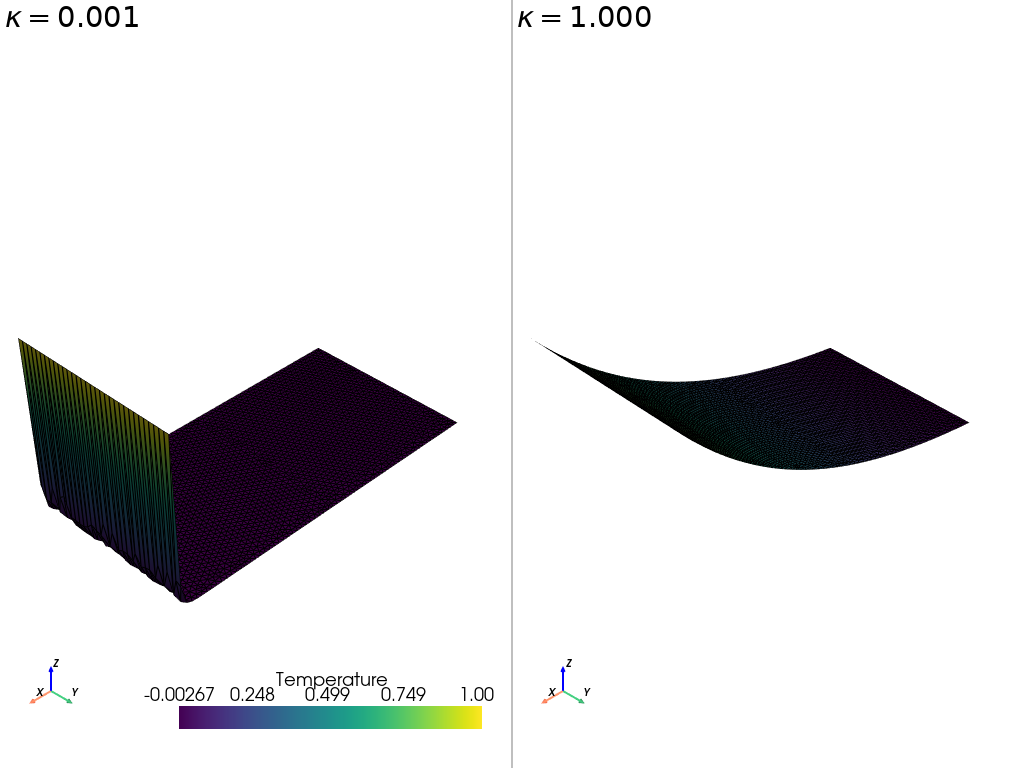

In [28]:
Lx, Ly = 2.0, 1.0
flag_refine_exit = False
flag_refine_interface = False
mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh", 1.0/32.0)
x = fd.SpatialCoordinate(mymesh)
Vh = fd.FunctionSpace(mymesh, "CG", degree=1)

#icase = 'REAC_BL'
icase = 'CONV_BL'
iestab = 'SUPG'
#iestab = 'NONE'

# Diffusive term
lkappa = [fd.Constant(0.001), fd.Constant(1.0)]
sigma_val = fd.Constant(0.0)
beta = fd.as_vector([1.0, 0.0])

plotter = pv.Plotter(shape=(1,2))
for i, kappa in enumerate(lkappa):

    Pe = fd.sqrt(beta[0]**2 + beta[1]**2) * Lx / kappa
    uex = fd.Function(Vh)
    uex.interpolate((fd.exp(Pe*x[0]/Lx) -1) / (fd.exp(Pe) - 1))
    uh = solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, f"Solutions/{float(kappa):.3f}.pvd")

    plot_function(f"Solutions/{float(kappa):.3f}.pvd", rf"$\kappa = {float(kappa):.3f}$", plotter, 0, i, True)
    print(f"kappa = {kappa} - H1 error = ", H1norm(uex - uh))
plotter.link_views()
plotter.show()



PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.0625 - H1 error =  1.0296174644901408


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.03125 - H1 error =  1.1129514231896886


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.015625 - H1 error =  0.7278029125765156


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.0078125 - H1 error =  0.3361942183575696


/tmp/ipykernel_90567/3218535899.py:30: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


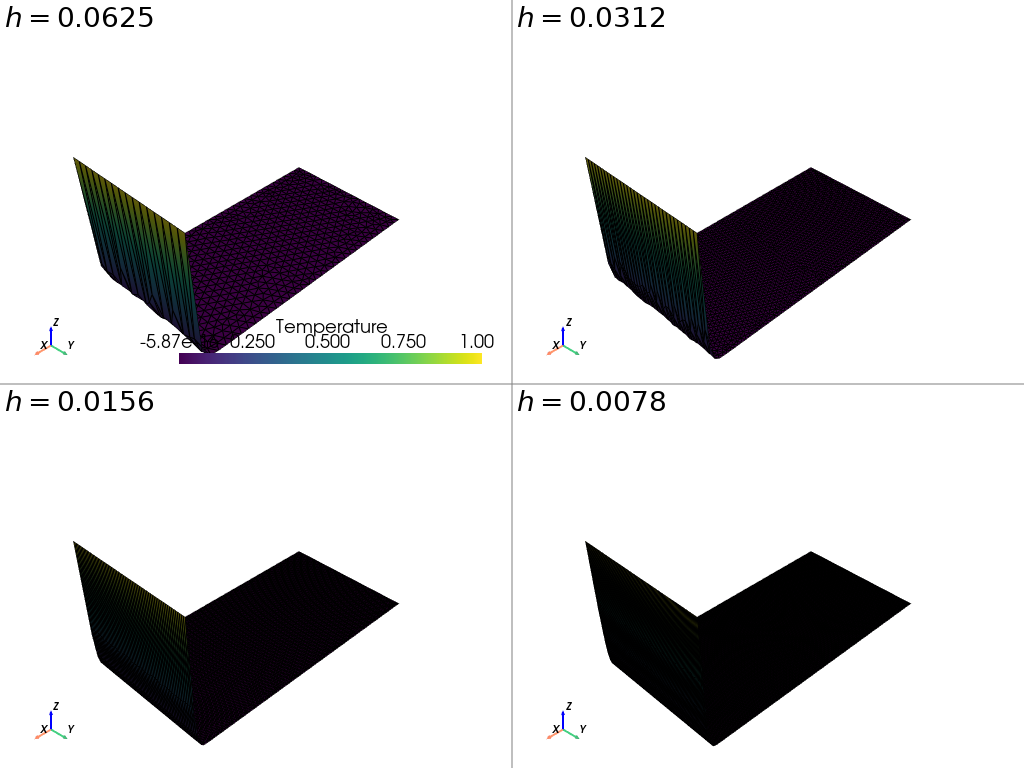

In [30]:
Lx, Ly = 2.0, 1.0
flag_refine_exit = False
flag_refine_interface = False


#icase = 'REAC_BL'
icase = 'CONV_BL'
iestab = 'SUPG'
#iestab = 'NONE'

# Diffusive term
kappa = fd.Constant(0.01)
sigma_val = fd.Constant(0.0)
beta = fd.as_vector([1.0, 0.0])

lh = [1.0/16.0, 1.0/32.0, 1.0/64.0, 1.0/128.0]

plotter = pv.Plotter(shape=(2,2))
for i, h in enumerate(lh):
    mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh", h)
    Vh = fd.FunctionSpace(mymesh, "CG", degree=1)
    Pe = fd.sqrt(beta[0]**2 + beta[1]**2) * Lx / kappa
    uex = fd.Function(Vh)
    uex.interpolate((fd.exp(Pe*x[0]/Lx) -1) / (fd.exp(Pe) - 1))
    uh = solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, f"Solutions/{h:.4f}.pvd")

    plot_function(f"Solutions/{h:.4f}.pvd", rf"$h = {h:.4f}$", plotter, i//2, i%2, True)
    print(f"h = {h} - H1 error = ", H1norm(uex - uh))
plotter.link_views()
plotter.show()

PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.0625 - H1 error =  1.0609348198036446
h = 0.03125 - H1 error =  0.8313291732668238


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.015625 - H1 error =  0.4177103059979438


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


h = 0.0078125 - H1 error =  0.21543282548332407


/tmp/ipykernel_90567/2439250658.py:30: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


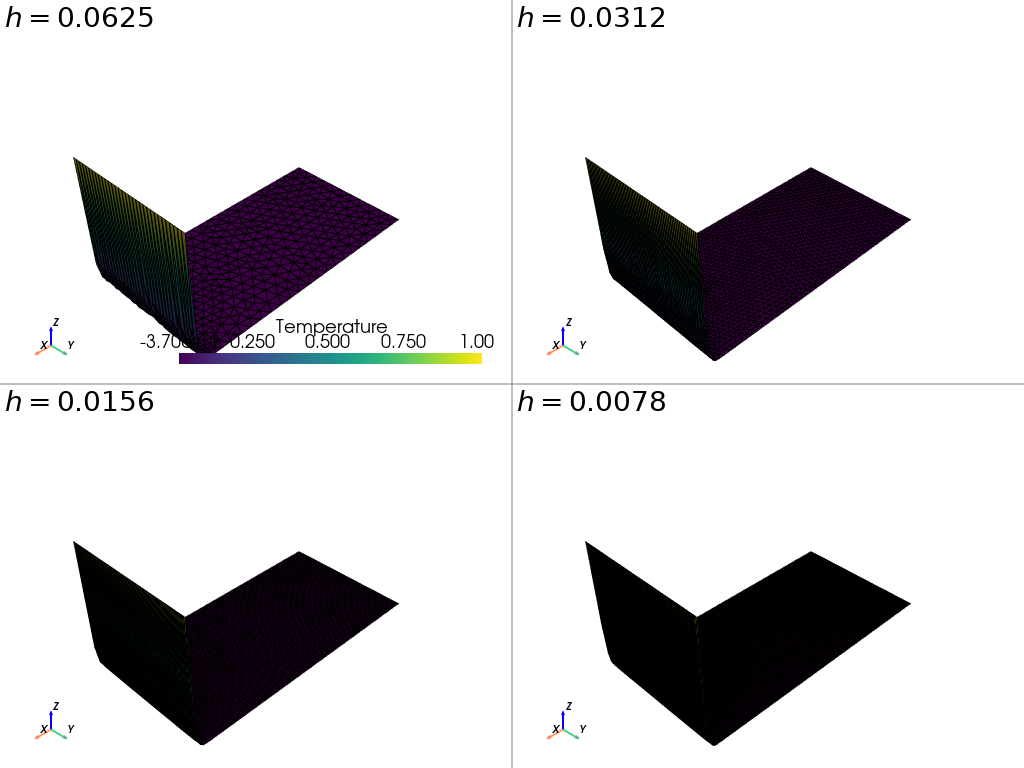

In [32]:
Lx, Ly = 2.0, 1.0
flag_refine_exit = True
flag_refine_interface = False


#icase = 'REAC_BL'
icase = 'CONV_BL'
iestab = 'SUPG'
#iestab = 'NONE'

# Diffusive term
kappa = fd.Constant(0.01)
sigma_val = fd.Constant(0.0)
beta = fd.as_vector([1.0, 0.0])

lh = [1.0/16.0, 1.0/32.0, 1.0/64.0, 1.0/128.0]

plotter = pv.Plotter(shape=(2,2))
for i, h in enumerate(lh):
    mymesh = CreateMesh(Lx, Ly, flag_refine_interface, flag_refine_exit, "Meshes/test.msh", h)
    Vh = fd.FunctionSpace(mymesh, "CG", degree=1)
    Pe = fd.sqrt(beta[0]**2 + beta[1]**2) * Lx / kappa
    uex = fd.Function(Vh)
    uex.interpolate((fd.exp(Pe*x[0]/Lx) -1) / (fd.exp(Pe) - 1))
    uh = solve_CDR(mymesh, icase, iestab, kappa, sigma_val, beta, f"Solutions/{h:.4f}.pvd")

    plot_function(f"Solutions/{h:.4f}.pvd", rf"$h = {h:.4f}$", plotter, i//2, i%2, True)
    print(f"h = {h} - H1 error = ", H1norm(uex - uh))
plotter.link_views()
plotter.show()

In general, for coarser grids, using the SUPG stabilization gives a better result, with smaller H1 error. But the convergence rate without SUPG is greater.